# CFEM royalties — who pays, for what, and how it changed

Analysis of `anm_cfem_arrecadacao`: the CFEM (financial compensation for mineral exploitation) collected by ANM, 2015 onwards. It reads the Parquet files from MinIO with pandas and plots with matplotlib.

> Required: run the CFEM pipeline (`01_anm_cfem.ipynb`) so the table exists.

**Read this before the numbers**
- The table holds the pipeline's *focus* only (P1/P2 priority substances, see the [README, section 3](README.md)), not every CFEM payment in Brazil. Totals here are totals **of the focus**.
- `valor_recolhido` is the amount **collected** in the month, not the value of the production.
- Months with far fewer rows than usual are treated as **partial** and left out of every comparison (section 1 shows which).

## 1. Load and check the months

The goal here is reading only the five columns we need and finding which months are complete, so a half-loaded month does not look like a collapse.

In [1]:
import os

import matplotlib.pyplot as plt
import matplotlib.ticker as mt
import pandas as pd
import s3fs

BASE = "lake/estudo/anm_cfem_arrecadacao"
fs = s3fs.S3FileSystem(client_kwargs={"endpoint_url": os.environ.get("S3_ENDPOINT", "http://minio:9000")},  # creds come from the environment
                       use_listings_cache=False)

df = pd.read_parquet(BASE, columns=["ano_mes", "uf", "municipio", "substancia", "valor_recolhido"], filesystem=fs)
df["valor_recolhido"] = df["valor_recolhido"].astype("float64")
df["ano_mes"] = pd.to_datetime(df["ano_mes"].astype(str))
df["ano"] = df["ano_mes"].dt.year

# a month is "complete" when it has at least half the rows of a typical recent month
mensal = df.groupby("ano_mes").agg(linhas=("valor_recolhido", "size"), valor=("valor_recolhido", "sum"))
tipico = mensal["linhas"].tail(24).median()
mensal["completo"] = mensal["linhas"] >= 0.5 * tipico

print(f"{len(df):,} rows, {df['ano_mes'].min():%Y-%m} to {df['ano_mes'].max():%Y-%m}; typical month = {tipico:.0f} rows")
print("partial or odd months:", [f"{d:%Y-%m} ({n} rows)" for d, n in mensal.loc[~mensal['completo'], 'linhas'].items()] or "none")

dfc = df[df["ano_mes"].isin(mensal.index[mensal["completo"]])]
meses_por_ano = dfc.groupby("ano")["ano_mes"].nunique()
anos_cheios = meses_por_ano[meses_por_ano == 12].index
ANO = anos_cheios.max()                        # latest full year
ano_parcial = dfc["ano"].max()                 # year in progress (may equal ANO)
ultimo_mes = dfc.loc[dfc["ano"] == ano_parcial, "ano_mes"].dt.month.max()
print(f"reference year: {ANO}; year in progress: {ano_parcial}, complete through month {ultimo_mes}")

43,767 rows, 2015-01 to 2026-10; typical month = 242 rows
partial or odd months: ['2026-07 (32 rows)', '2026-10 (2 rows)']
reference year: 2025; year in progress: 2026, complete through month 6


## 2. Total per year

One bar per full year. The line below the chart compares the year in progress with the same months of the previous year, which is the fair way to read a year that is not over.

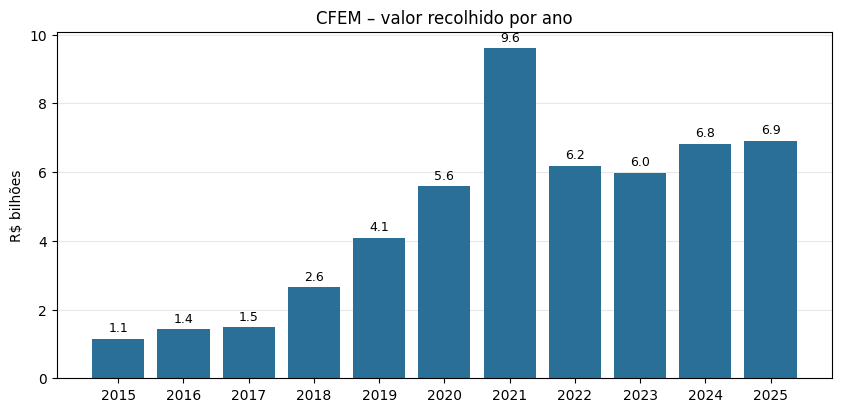

2026, months 1-6: R$ 3.34 bi vs R$ 3.23 bi in 2025 (+3.3%)


In [2]:
anual = dfc[dfc["ano"].isin(anos_cheios)].groupby("ano")["valor_recolhido"].sum() / 1e9

fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.bar(anual.index, anual.values, color="#2a6f97")
ax.bar_label(bars, labels=[f"{v:.1f}" for v in anual.values], padding=3, fontsize=9)
ax.set_title("CFEM – valor recolhido por ano")
ax.set_ylabel("R$ bilhões")
ax.set_xticks(anual.index)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
plt.show()

if ano_parcial != ANO or ultimo_mes < 12:
    meses = range(1, ultimo_mes + 1)
    atual = dfc[(dfc["ano"] == ano_parcial) & dfc["ano_mes"].dt.month.isin(meses)]["valor_recolhido"].sum()
    antes = dfc[(dfc["ano"] == ano_parcial - 1) & dfc["ano_mes"].dt.month.isin(meses)]["valor_recolhido"].sum()
    print(f"{ano_parcial}, months 1-{ultimo_mes}: R$ {atual/1e9:.2f} bi vs R$ {antes/1e9:.2f} bi in {ano_parcial-1} ({atual/antes-1:+.1%})")

## 3. Month by month

The monthly series is noisy; the 12-month average shows the trend. The dashed vertical line marks the last complete month.

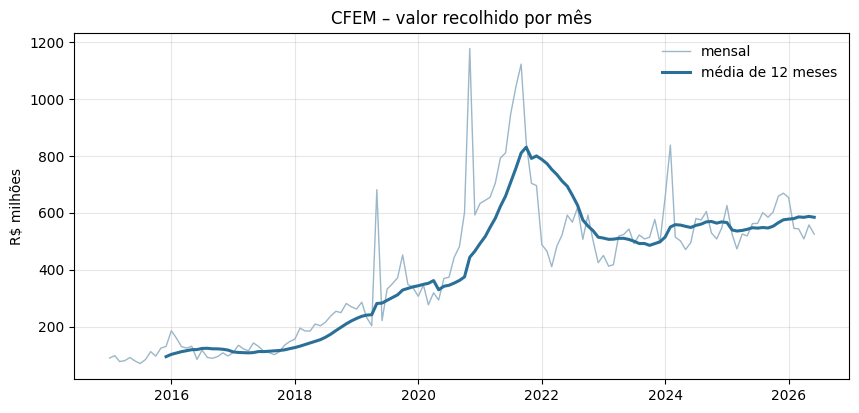

In [3]:
m = mensal[mensal["completo"]]["valor"] / 1e6
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(m.index, m.values, color="#9bb7c9", lw=1, label="mensal")
ax.plot(m.index, m.rolling(12).mean(), color="#2a6f97", lw=2.2, label="média de 12 meses")
ax.set_title("CFEM – valor recolhido por mês")
ax.set_ylabel("R$ milhões")
ax.grid(alpha=0.3)
ax.legend(frameon=False)
plt.show()

## 4. By substance

Which minerals generate the royalty. Iron is the large block; the others are an order of magnitude smaller.

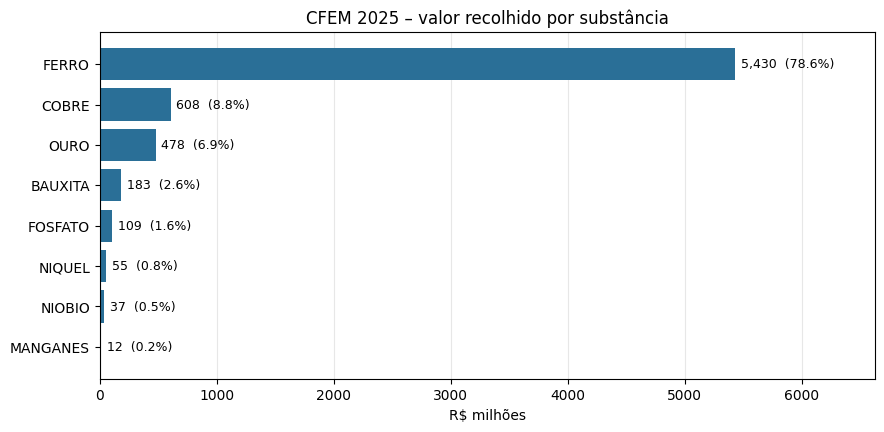

In [4]:
ref = dfc[dfc["ano"] == ANO]
sub = ref.groupby("substancia")["valor_recolhido"].sum().sort_values() / 1e6
pct = sub / sub.sum() * 100

fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.barh(sub.index, sub.values, color="#2a6f97")
ax.bar_label(bars, labels=[f"{v:,.0f}  ({p:.1f}%)" for v, p in zip(sub.values, pct.values)], padding=4, fontsize=9)
ax.set_title(f"CFEM {ANO} – valor recolhido por substância")
ax.set_xlabel("R$ milhões")
ax.set_xlim(0, sub.max() * 1.22)
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)
plt.show()

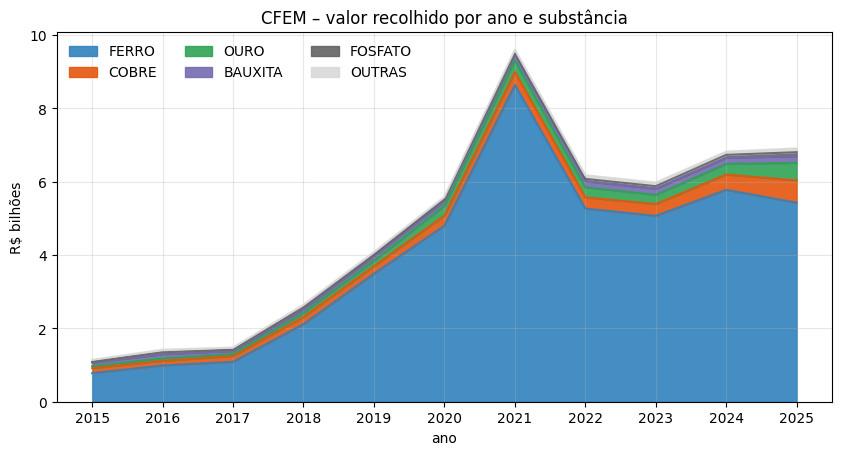

ano,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
parte do ferro,68.4%,69.9%,73.8%,80.1%,85.6%,86.0%,90.0%,85.3%,84.8%,84.7%,78.6%


In [5]:
# the same split over time: top 5 substances plus "OUTRAS"
cheios = dfc[dfc["ano"].isin(anos_cheios)]
top5 = cheios.groupby("substancia")["valor_recolhido"].sum().nlargest(5).index
mix = (cheios.assign(grupo=cheios["substancia"].where(cheios["substancia"].isin(top5), "OUTRAS"))
       .pivot_table(index="ano", columns="grupo", values="valor_recolhido", aggfunc="sum") / 1e9)
mix = mix[list(top5) + ["OUTRAS"]]

ax = mix.plot.area(figsize=(10, 4.8), alpha=0.9, colormap="tab20c")
ax.set_title("CFEM – valor recolhido por ano e substância")
ax.set_ylabel("R$ bilhões")
ax.set_xticks(mix.index)
ax.legend(frameon=False, ncol=3, loc="upper left")
ax.grid(alpha=0.3)
plt.show()

# how much of each year is iron
(ferro := cheios[cheios["substancia"] == "FERRO"].groupby("ano")["valor_recolhido"].sum() / cheios.groupby("ano")["valor_recolhido"].sum()).map("{:.1%}".format).to_frame("parte do ferro").T

## 5. By state and municipality

Where the royalty is collected. The first chart is the state ranking of the reference year; the second shows how much Minas Gerais and Pará hold together over time.

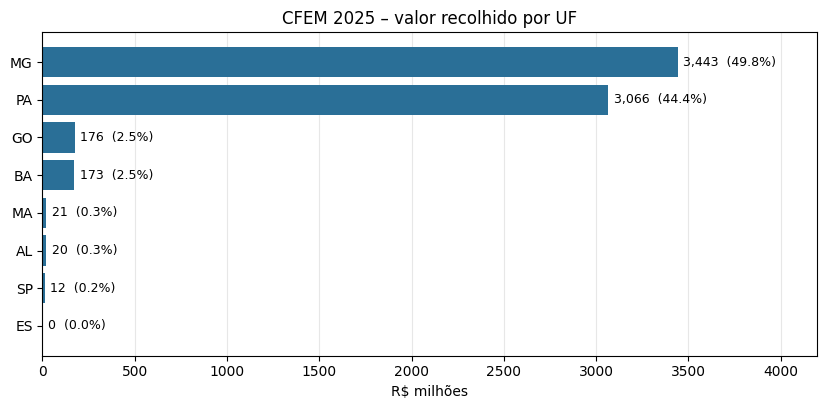

In [6]:
uf = ref.groupby("uf")["valor_recolhido"].sum().sort_values() / 1e6
pct = uf / uf.sum() * 100

fig, ax = plt.subplots(figsize=(10, 4.2))
bars = ax.barh(uf.index, uf.values, color="#2a6f97")
ax.bar_label(bars, labels=[f"{v:,.0f}  ({p:.1f}%)" for v, p in zip(uf.values, pct.values)], padding=4, fontsize=9)
ax.set_title(f"CFEM {ANO} – valor recolhido por UF")
ax.set_xlabel("R$ milhões")
ax.set_xlim(0, uf.max() * 1.22)
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)
plt.show()

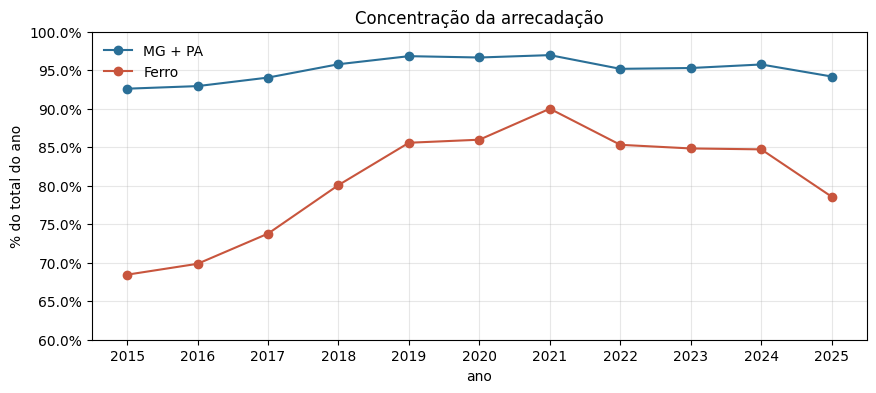

In [7]:
tot = cheios.groupby("ano")["valor_recolhido"].sum()
conc = pd.DataFrame({
    "MG + PA": cheios[cheios["uf"].isin(["MG", "PA"])].groupby("ano")["valor_recolhido"].sum() / tot * 100,
    "Ferro": cheios[cheios["substancia"] == "FERRO"].groupby("ano")["valor_recolhido"].sum() / tot * 100,
})
ax = conc.plot(figsize=(10, 4), marker="o", color=["#2a6f97", "#c8553d"])
ax.set_title("Concentração da arrecadação")
ax.set_ylabel("% do total do ano")
ax.set_ylim(60, 100)
ax.set_xticks(conc.index)
ax.yaxis.set_major_formatter(mt.PercentFormatter())
ax.legend(frameon=False)
ax.grid(alpha=0.3)
plt.show()

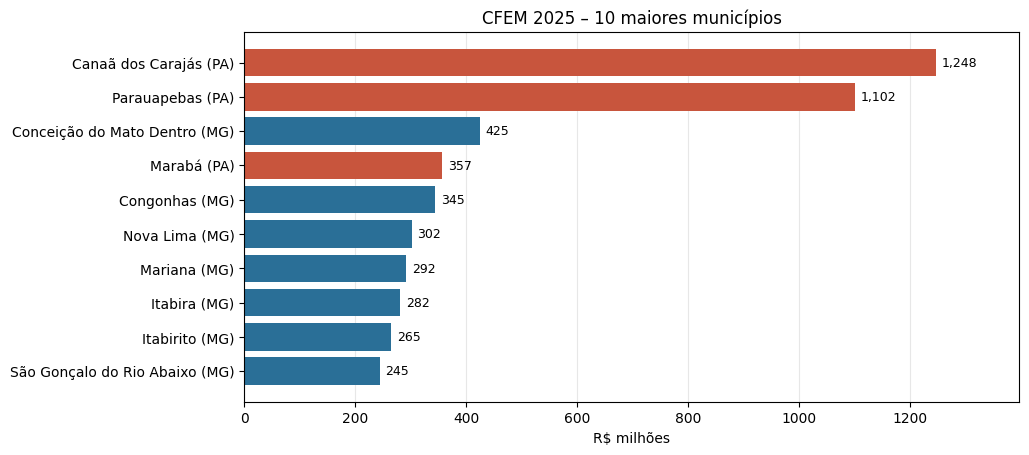

In [8]:
mun = (ref.groupby(["uf", "municipio"])["valor_recolhido"].sum().nlargest(10).sort_values() / 1e6).reset_index()
cor = {"PA": "#c8553d", "MG": "#2a6f97"}

fig, ax = plt.subplots(figsize=(10, 4.8))
bars = ax.barh(mun["municipio"] + " (" + mun["uf"] + ")", mun["valor_recolhido"], color=[cor.get(u, "#888") for u in mun["uf"]])
ax.bar_label(bars, labels=[f"{v:,.0f}" for v in mun["valor_recolhido"]], padding=4, fontsize=9)
ax.set_title(f"CFEM {ANO} – 10 maiores municípios")
ax.set_xlabel("R$ milhões")
ax.set_xlim(0, mun["valor_recolhido"].max() * 1.12)
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)
plt.show()

## 6. What the data says

Numbers below were read from the lake when this notebook was written (full years through 2025; 2026 complete through June). Re-run the cells to refresh the charts; update this text if the data is reloaded.

- **Size.** About **R$ 6.9 bn** collected in 2025, from R$ 1.1 bn in 2015. The growth came in steps: 2018–2021 rose every year, 2021 peaked at **R$ 9.6 bn**, and since 2022 the level has stayed at about R$ 6.0–6.9 bn (2025 is the highest of those).
- **2021 was an iron year.** Iron went from R$ 4.8 bn (2020) to R$ 8.6 bn (2021), then back to R$ 5.3 bn (2022). Copper and gold moved far less (about R$ 0.27→0.35→0.30 bn and R$ 0.27→0.31→0.28 bn). The peak is therefore mostly one substance. This notebook does not include prices or volumes, so it shows *that* iron drove it, not *why*; the production tables (`anm_amb_producao`) are the place to look.
- **Concentration.** Iron is **78.6%** of 2025 and Minas Gerais plus Pará are **94.2%**. Both shares were higher in 2019–2021 (iron 85.6–90.0%, MG + PA about 97%) and have eased since; copper (8.8%) and gold (6.9%) are the next two.
- **Where.** In 2025 the two biggest municipalities are both in Pará: **Canaã dos Carajás (R$ 1.25 bn)** and **Parauapebas (R$ 1.10 bn)**, together about three quarters of Pará's total. Then comes Conceição do Mato Dentro (MG, R$ 0.42 bn), Marabá (PA, R$ 0.36 bn), and Minas Gerais again: Congonhas, Nova Lima, Mariana and Itabira.
- **2026 so far.** January–June 2026 is running at roughly R$ 0.5–0.65 bn a month (R$ 3.34 bn for the six months), **+3.3%** over January–June 2025 (R$ 3.23 bn).

**Limits.** Focus-only table (see the top); CFEM collected, not production value; July–October 2026 are not loaded yet, so any "year to date" must stop at June.